In [21]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [22]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *


from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )

from f2_utils import *
import time_in_each_roi

In [23]:
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"


In [24]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))

    if if_return_map ==True:
        return std_map
    else:
        plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
        plt.axis('off')
        plt.colorbar()
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model


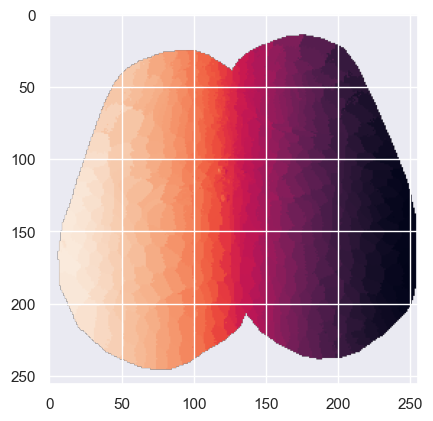

In [25]:
mouse='cm193'
with h5py.File(step_0_root+mouse+'/'+'idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [26]:
load_path = str(PREPARES / "registration") + "/"
dict_transform = load_model(load_path+'dict_transform')
M=dict_transform[mouse]


# 1. spontaneous running

In [27]:
bodyparts = ['RFP','LFP','RHP','LHP','nose','mouth','tail','RW','LW']
day2_dict = { 'runU':
    "boop_on = 'RFP';stim_frames_raw="+"[1950 3712 5480 7302 9114 10930 12716 14508 16300];".replace(" ",","),
 'runV':
    "boop_on = 'LFP';stim_frames_raw="+"[1832 3682 5432 7208 9044 10812 12598 14396 16230];".replace(" ",","),
 'runW':
    "boop_on = 'nose';stim_frames_raw="+"[1832 3612 5392 7212 9016 10770 12594 14402 16198];".replace(" ",","),
 'runX':
    "boop_on = 'RHP';stim_frames_raw="+"[1844 3636 5452 7234 9036 10856 12620 14432 16274];".replace(" ",","),
 'runY':
    "boop_on = 'LHP';stim_frames_raw="+"[1820 3610 5413 7218 9002 10802 12610 14392 ];".replace(" ",","),
 'runZ':
    "boop_on = 'mouth';stim_frames_raw="+"[1834 3614 7194 9034 10808 12619 14470 16206];".replace(" ",","),
 'runAA':
    "boop_on = 'tail';stim_frames_raw="+"[1832 3606 5384 7200 9036 10788 12544 14392 16186];".replace(" ",",")}
day3_dict = {
     'runL':"boop_on = 'RHP';stim_frames_raw="+"[1848 3656 5432 7228 9020 10836 12636 14396 16248];".replace(" ",","),
    'runM':"boop_on = 'LHP';stim_frames_raw="+"[1812 3610 5408 7188 9004 10802 12612 14400 16206];".replace(" ",","),
    'runN':"boop_on = 'nose';stim_frames_raw="+"[1874 3692 5424 7202 9038 10808 12592 14410 16184];".replace(" ",","),
    'runO':"boop_on = 'RFP';stim_frames_raw="+"[1800 3612 5406 7208 9004 10798 12592 14396 16206];".replace(" ",","),
    'runP':"boop_on = 'LFP';stim_frames_raw="+"[1828 3632 5420 7200 8996 10806 12612 14416 16200];".replace(" ",","),
    'runQ':"boop_on = 'mouth';stim_frames_raw="+"[1890 3820 7200 9022 10796 12566 14320 16166];".replace(" ",","),
    'runR':"boop_on = 'tail';stim_frames_raw="+"[1800 3624 5388 7200 9000 10800 12594 14382 16180];".replace(" ",","),
    'runS':"boop_on = 'RW';stim_frames_raw="+"[1832 3620 5388 7190 8972 10788 12600 14424 16250];".replace(" ",","),
    'runT':"boop_on = 'LW';stim_frames_raw="+"[1805 3577 5355 7163 8965 10750 12619 14350 16153];".replace(" ",","),
    'runU':"boop_on = 'mouth';stim_frames_raw="+"[5472 7170 9000 10772 12548 14404];".replace(" ",","),
}
day4_dict = {
     'runJ':"boop_on = 'mouth';stim_frames_raw="+"[1894 3670 5444 7240 9058 10874 12636 14442 16224];".replace(" ",","),
    # 'runK':"boop_on = 'RW';stim_frames_raw="+"[1836 3600 5360 7154 9064 10800 12600 14400 16188];".replace(" ",","),
#     'runL':"boop_on = 'LW';stim_frames_raw="+"[1836 3620 5444 7218 9016 10786 12624 14400 16200];".replace(" ",","),
    'runM':"boop_on = 'mouth';stim_frames_raw="+"[1880 3602 5490 7196 10892 12594 14360 16196];".replace(" ",",")
}

In [28]:
step_1_root+"*/[2]/H_run[U-Z]*.mat"


'/Volumes/WX/scratch/steps_data/step_1/*/[2]/H_run[U-Z]*.mat'

In [29]:
mouse = 'cm193'
f0 = [f for f in glob.glob(step_1_root+"*/[2]/run[U-V]*.mat", recursive=True)] 
f1 = [f for f in glob.glob(step_1_root+"*/[2]/run[W-Z]*.mat", recursive=True)] 
f2 = [f for f in glob.glob(step_1_root+"*/[2]/runAA*.mat", recursive=True)]
f3 = [f for f in glob.glob(step_1_root+"*/[3]/run[L-U]*.mat", recursive=True)]
f4 = [f for f in glob.glob(step_1_root+"*/[4]/run[J]*.mat", recursive=True)]
f5 = [f for f in glob.glob(step_1_root+"*/[4]/run[M]*.mat", recursive=True)]
file_spont = f0+f1+f2+f3+f4+f5
file_spont

['/Volumes/WX/scratch/steps_data/step_1/cm193/2/runU_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/2/runV_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/2/runX_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/2/runW_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/2/runZ_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/2/runY_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/2/runAA_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/3/runP_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/3/runN_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/3/runU_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/3/runL_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/3/runR_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/3/runT_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/3/runQ_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm193/3/runO_stim_1.mat',
 '/Volume

In [30]:
sns.set()
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

T_PRE = 100
T_POST = 200
T = T_PRE+T_POST
num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1)))) 

M_jrgeco = {key:np.empty((256,256,T,0)) for key in bodyparts}
M_day_label = {key:np.empty((0)) for key in bodyparts}

for i_file,fname in enumerate(file_spont): 
    ################################### identity 
    mouse = fname.split('step_1/')[1][0:5]
    day = fname.split(mouse)[1][1:2]
    mouse_day = mouse+'_'+day
    run_name = fname.split('_stim_1')[0].split('/'+day+'/')[1]
    run = run_name


    if day=='2':
        exec(day2_dict[run]);print(day2_dict[run][:15])
    elif day=='3':
        exec(day3_dict[run]);print(day3_dict[run][:15])
    elif day=='4':
        exec(day4_dict[run]);print(day4_dict[run][:15])
        
    stim_frames = np.round(np.array(stim_frames_raw)/3,decimals=-1).astype('int')
   
    total_frames = 5470
    start_stop_ind = pd.DataFrame(stim_frames)
    start_stop_ind = start_stop_ind[start_stop_ind[0]<total_frames-T_POST]
    for i in range(len(start_stop_ind)):
        
        cut_range = range(start_stop_ind.iloc[i,0]-T_PRE,start_stop_ind.iloc[i,0]+T_POST)

        with h5py.File(fname, "r") as f_H:
            m = f_H['m']
            C = np.array(f_H['C']['jrgeco'])
            S = np.array(f_H['S']['jrgeco'])[cut_range,:]
            # cut [-60,60] frames slice
            mask = np.array(f_H['mask'])
            # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
            nanidx = np.squeeze(m['nanidx'])==1
            CS = np.dot(S,C).transpose()
            jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
            jrgeco[:] = np.nan
            jrgeco[nanidx==True,:] = CS
            jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

        jrgeco_dsl = jrgeco-np.mean(jrgeco[:,:,:80],axis=2)[:,:,np.newaxis]
        M_jrgeco[boop_on] = np.append(M_jrgeco[boop_on],jrgeco_dsl[:,:,:,np.newaxis],axis=3)
        M_day_label[boop_on] = np.append(M_day_label[boop_on],mouse_day+'_'+run)



boop_on = 'RFP'
boop_on = 'LFP'
boop_on = 'RHP'
boop_on = 'nose
boop_on = 'mout
boop_on = 'LHP'
boop_on = 'tail
boop_on = 'LFP'
boop_on = 'nose
boop_on = 'mout
boop_on = 'RHP'
boop_on = 'tail
boop_on = 'LW';
boop_on = 'mout
boop_on = 'RFP'
boop_on = 'LHP'
boop_on = 'RW';
boop_on = 'mout
boop_on = 'mout
boop_on = 'mout
boop_on = 'mout


In [31]:
from skimage import measure

In [32]:
sns.set_style("whitegrid", {'axes.grid' : False})
avg_brain_maps = {key:[] for key in bodyparts}
contours = {key:[] for key in bodyparts}
clean_contours = {key:[] for key in bodyparts}
# brightest_ind = {key:[] for key in bodyparts}
vmax_dict = {key:[] for key in bodyparts}
t_range_dict = {key:[] for key in bodyparts}
homunculus_rois = {key:[] for key in bodyparts}


In [33]:
from sklearn.preprocessing import minmax_scale


In [34]:
def build_bodypart_roi(
    name,
    t_range,
    vmax,
    bw_threshold,
    reject_contour,
    focus_range=(0.1, 1),
    title=None,
    show_bw_preview=True,
    abs_signal=False,
    mask_crop=None,
    source_key=None,
    stat_key=None,
    vmin=0,
    select_bouts=None,
    precomputed_brain_map=None,
    skip_clean=False,
):
    # stat_key lets vmax_dict/t_range_dict be written under a different key than `name`
    # -- used when deriving one body part's ROI from another's brain_map (e.g. LV from LW).
    t_range_dict[stat_key or name] = t_range
    if precomputed_brain_map is not None:
        brain_map = precomputed_brain_map
    else:
        signal = M_jrgeco[source_key or name]
        if select_bouts is not None:
            signal = signal[:, :, :, select_bouts]
        if abs_signal:
            signal = np.abs(signal)
        brain_map = np.mean(np.mean(signal, axis=-1)[:, :, t_range], axis=-1)
        brain_map = cv2.warpAffine(brain_map, M[0:2, :], (256, 256))
    vmax_dict[stat_key or name] = vmax

    plt.figure(figsize=(8, 3), dpi=300)
    plt.subplot(121)
    plt.imshow(brain_map, vmin=vmin, vmax=vmax, cmap='coolwarm')
    plt.colorbar()
    plt.xticks([]); plt.yticks([])
    plt.title(title or name)

    plt.subplot(122)
    bw = brain_map > bw_threshold
    if show_bw_preview:
        plt.imshow(bw)
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(bw)
    contours[name] = measure.find_contours(filled_bw, 0.8)

    if skip_clean:
        # This body part's original cell computed contours but never filtered/plotted
        # them -- clean_contours[name] stays at its initialized [] and homunculus_rois[name]
        # is never written. Preserved here rather than silently filling in the gap.
        avg_brain_maps[name] = brain_map
        return brain_map

    if mask_crop is not None:
        filled_bw = mask_crop(filled_bw)

    filled_bw_nan = filled_bw.astype('float')
    filled_bw_nan[filled_bw_nan == 0] = np.nan
    focus_map = np.multiply(filled_bw_nan, brain_map)
    shape = focus_map.shape
    focus_map_scaled = minmax_scale(focus_map.ravel(), feature_range=focus_range).reshape(shape)
    plt.imshow(focus_map_scaled)
    homunculus_rois[name] = focus_map_scaled

    clean_contours[name] = [c for c in contours[name] if not reject_contour(c)]
    for c in clean_contours[name]:
        plt.plot(c[:, 1], c[:, 0], linewidth=2)

    avg_brain_maps[name] = brain_map
    return brain_map


def _reject_default(contour, min_len=20, row_cutoff=230):
    return len(contour) < min_len or np.any(contour[:, 0] > row_cutoff)


def _crop_rows(filled_bw, keep_below):
    filled_bw = filled_bw.copy()
    filled_bw[keep_below:, :] = False
    return filled_bw


def _crop_lv_from_lw(filled_bw):
    filled_bw = filled_bw.copy()
    filled_bw[:173, :] = False
    filled_bw[:, :150] = False
    return filled_bw


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

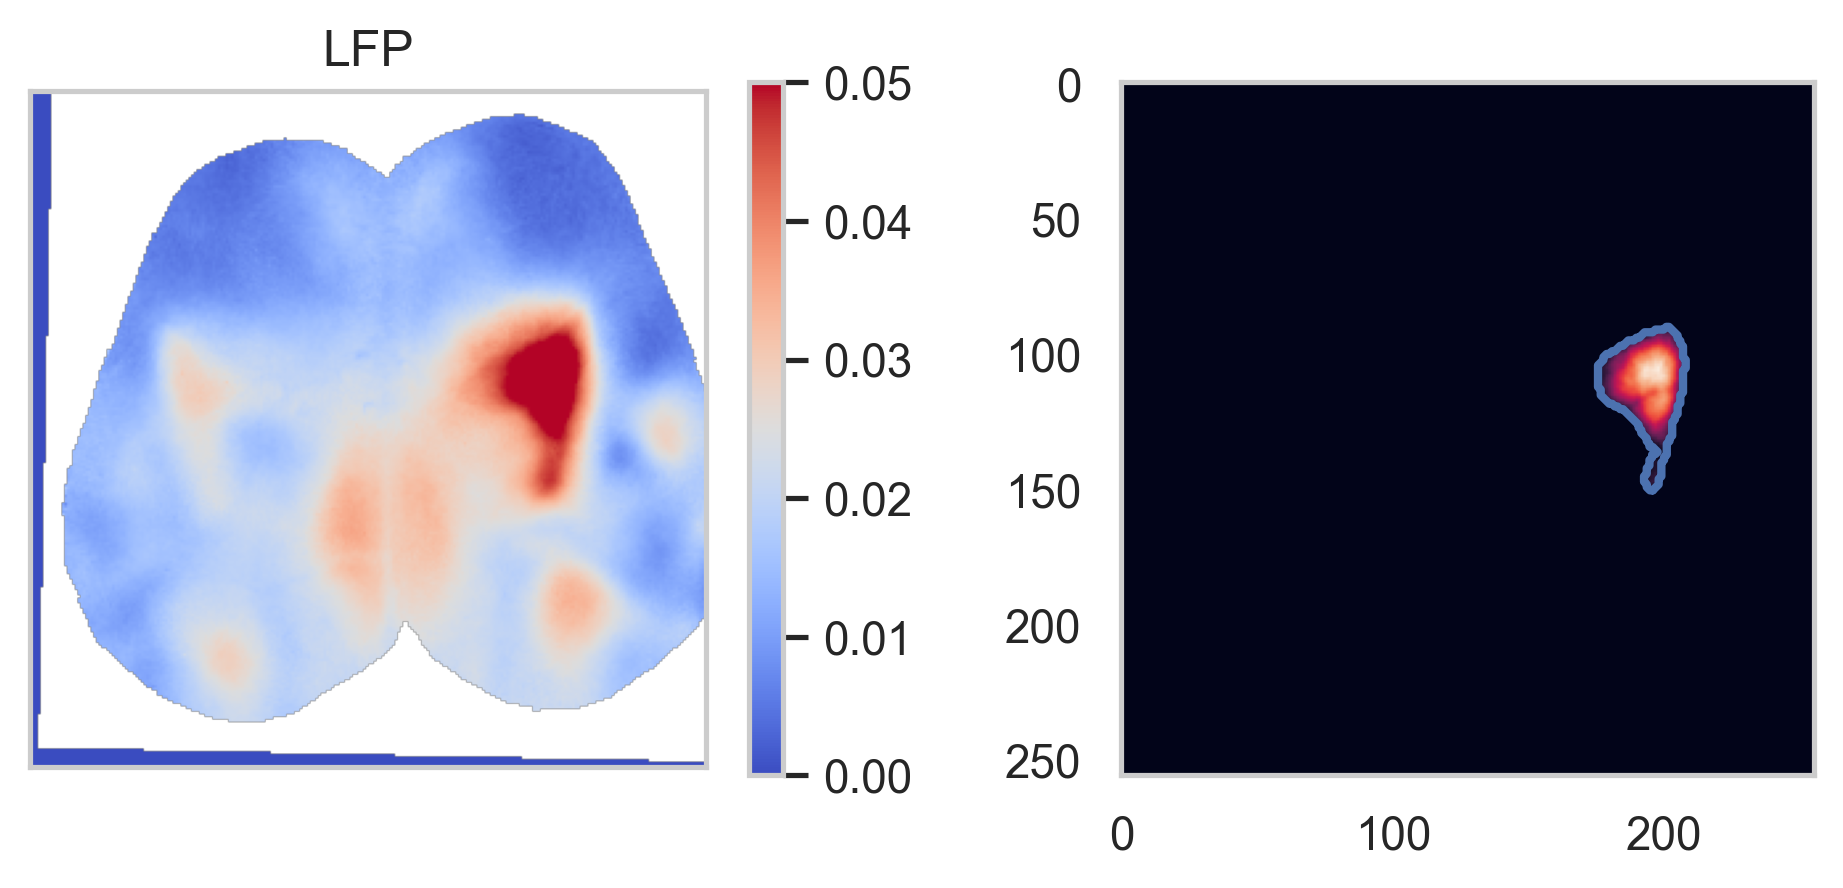

In [35]:
build_bodypart_roi(
    'LFP', range(T_PRE, T_PRE + 10), vmax=0.05, bw_threshold=0.045,
    reject_contour=_reject_default,
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

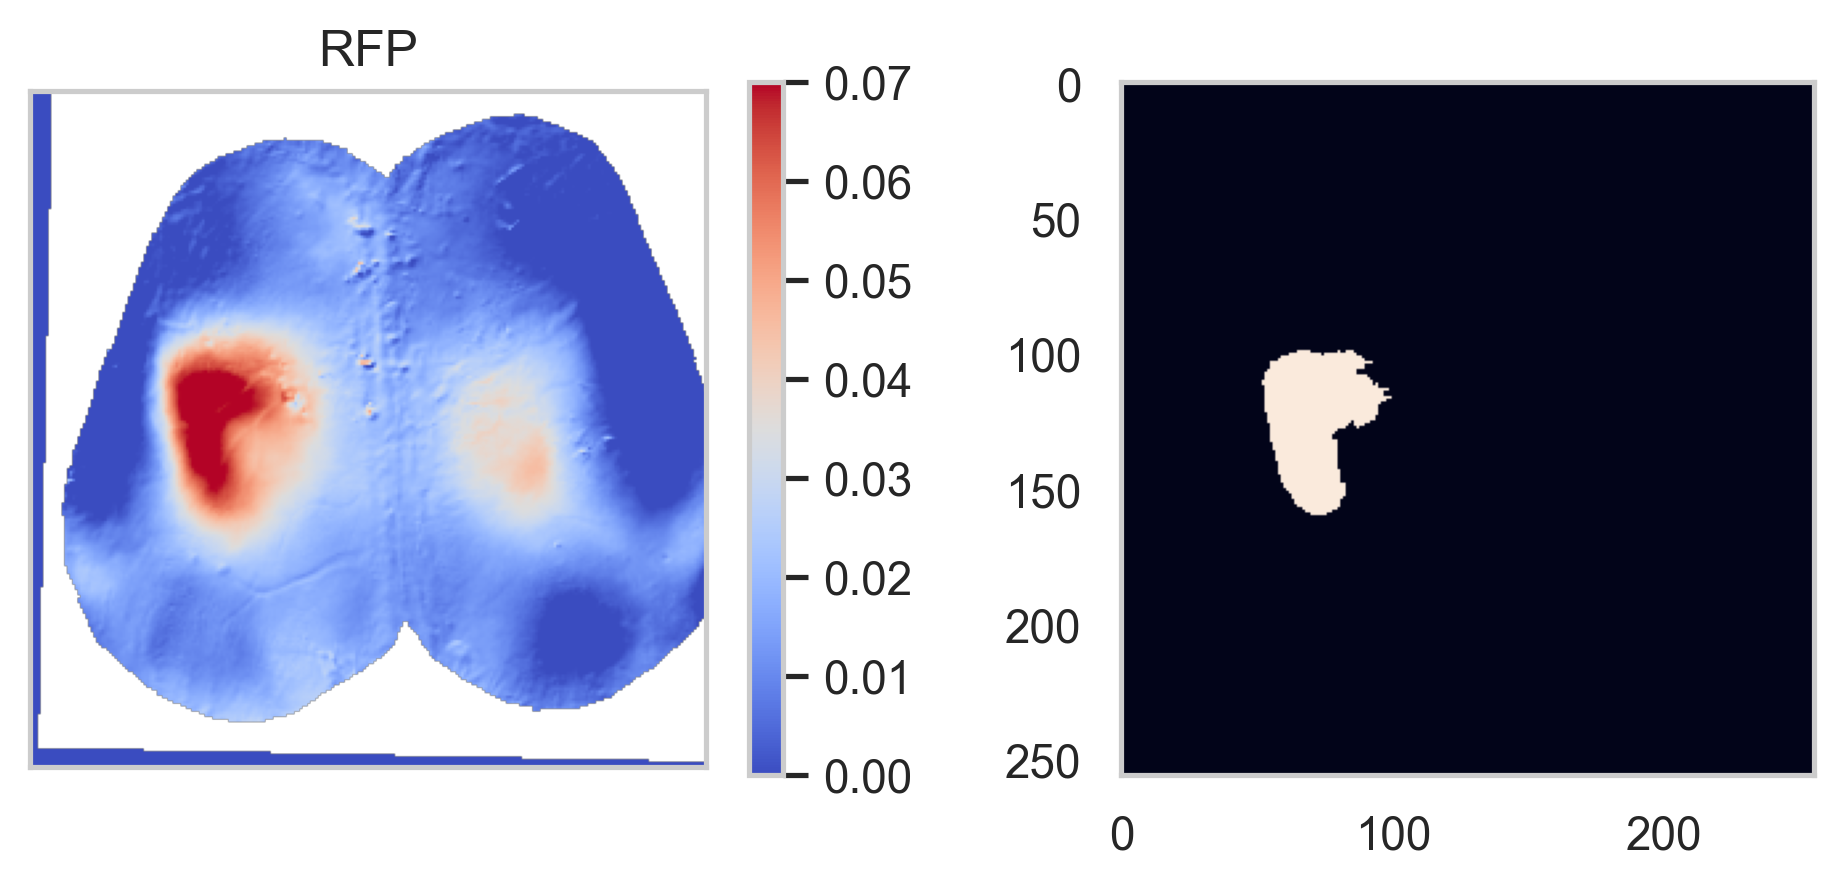

In [36]:
build_bodypart_roi(
    'RFP', range(T_PRE, T_PRE + 50), vmax=0.07, bw_threshold=0.053,
    reject_contour=_reject_default, skip_clean=True,
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

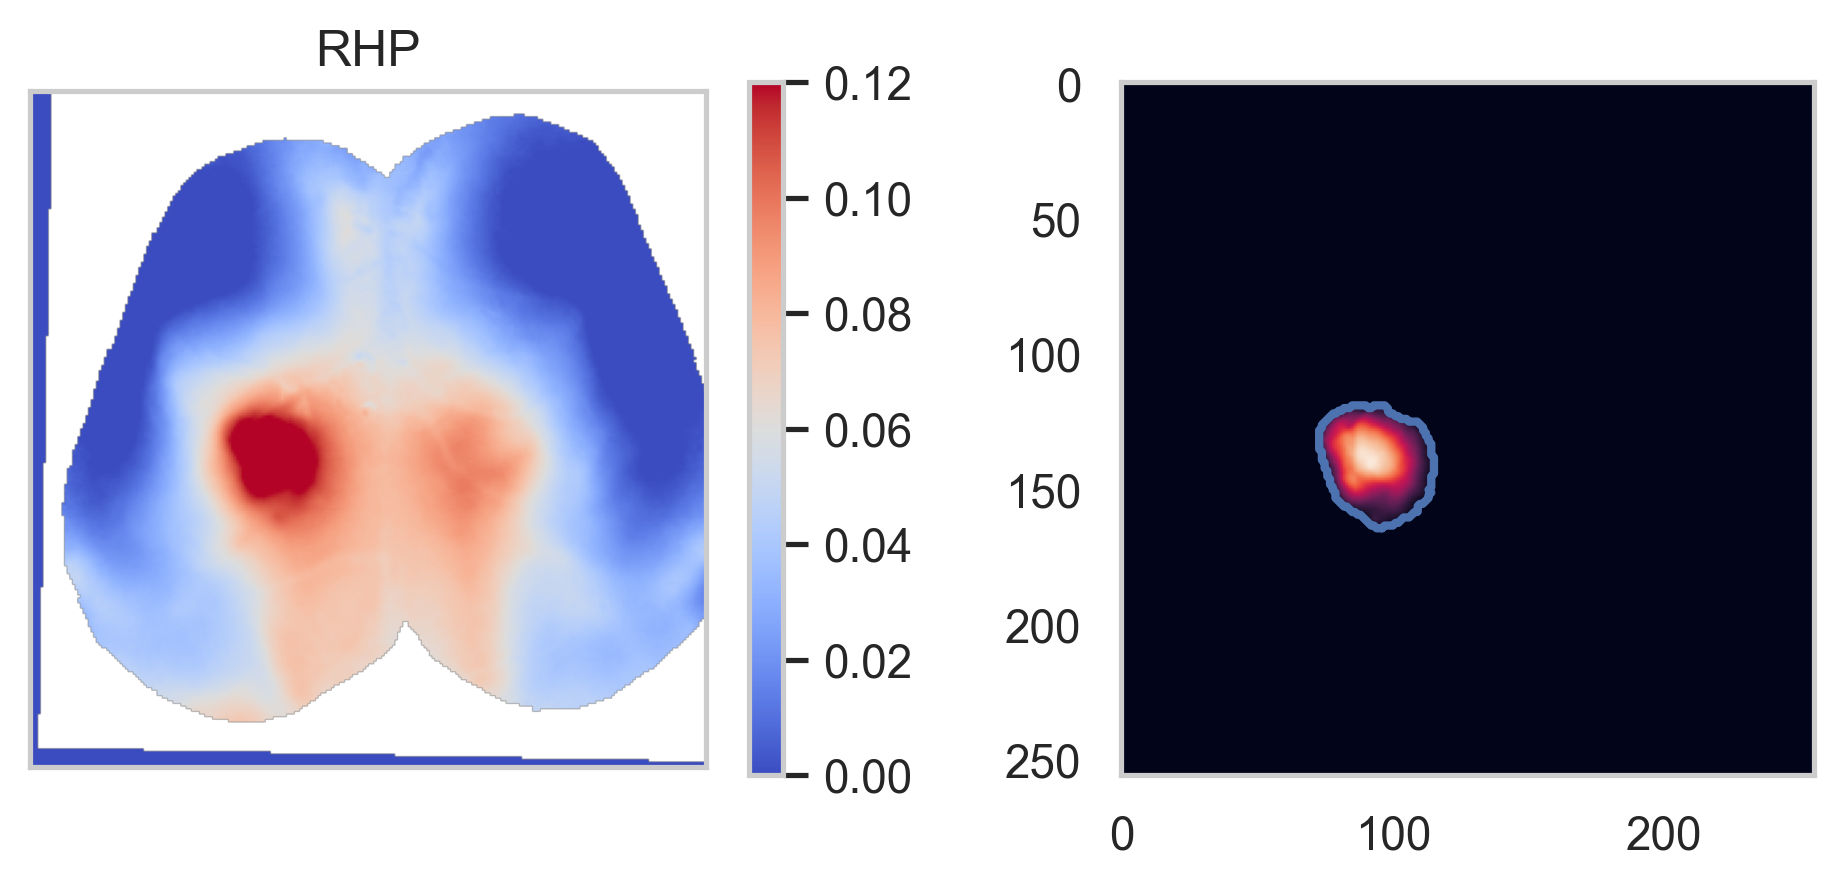

In [37]:
build_bodypart_roi(
    'RHP', range(T_PRE, T_PRE + 30), vmax=0.12, bw_threshold=0.1,
    reject_contour=_reject_default,
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

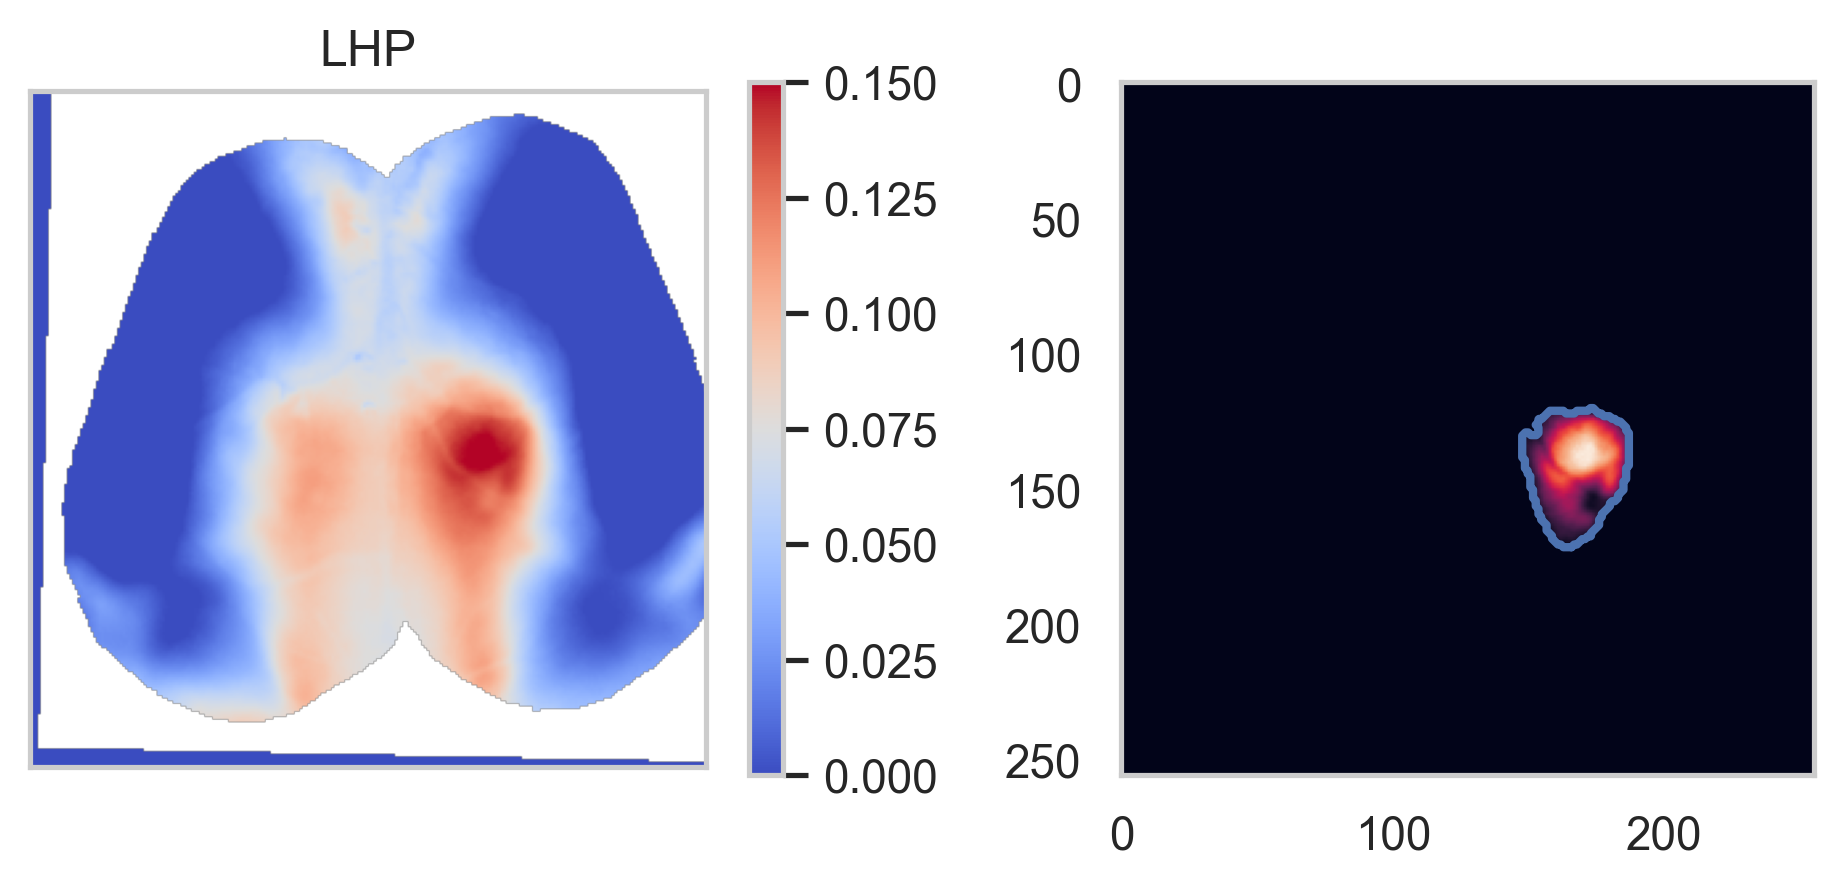

In [38]:
build_bodypart_roi(
    'LHP', range(T_PRE, T_PRE + 70), vmax=0.15, bw_threshold=0.12,
    reject_contour=_reject_default,
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

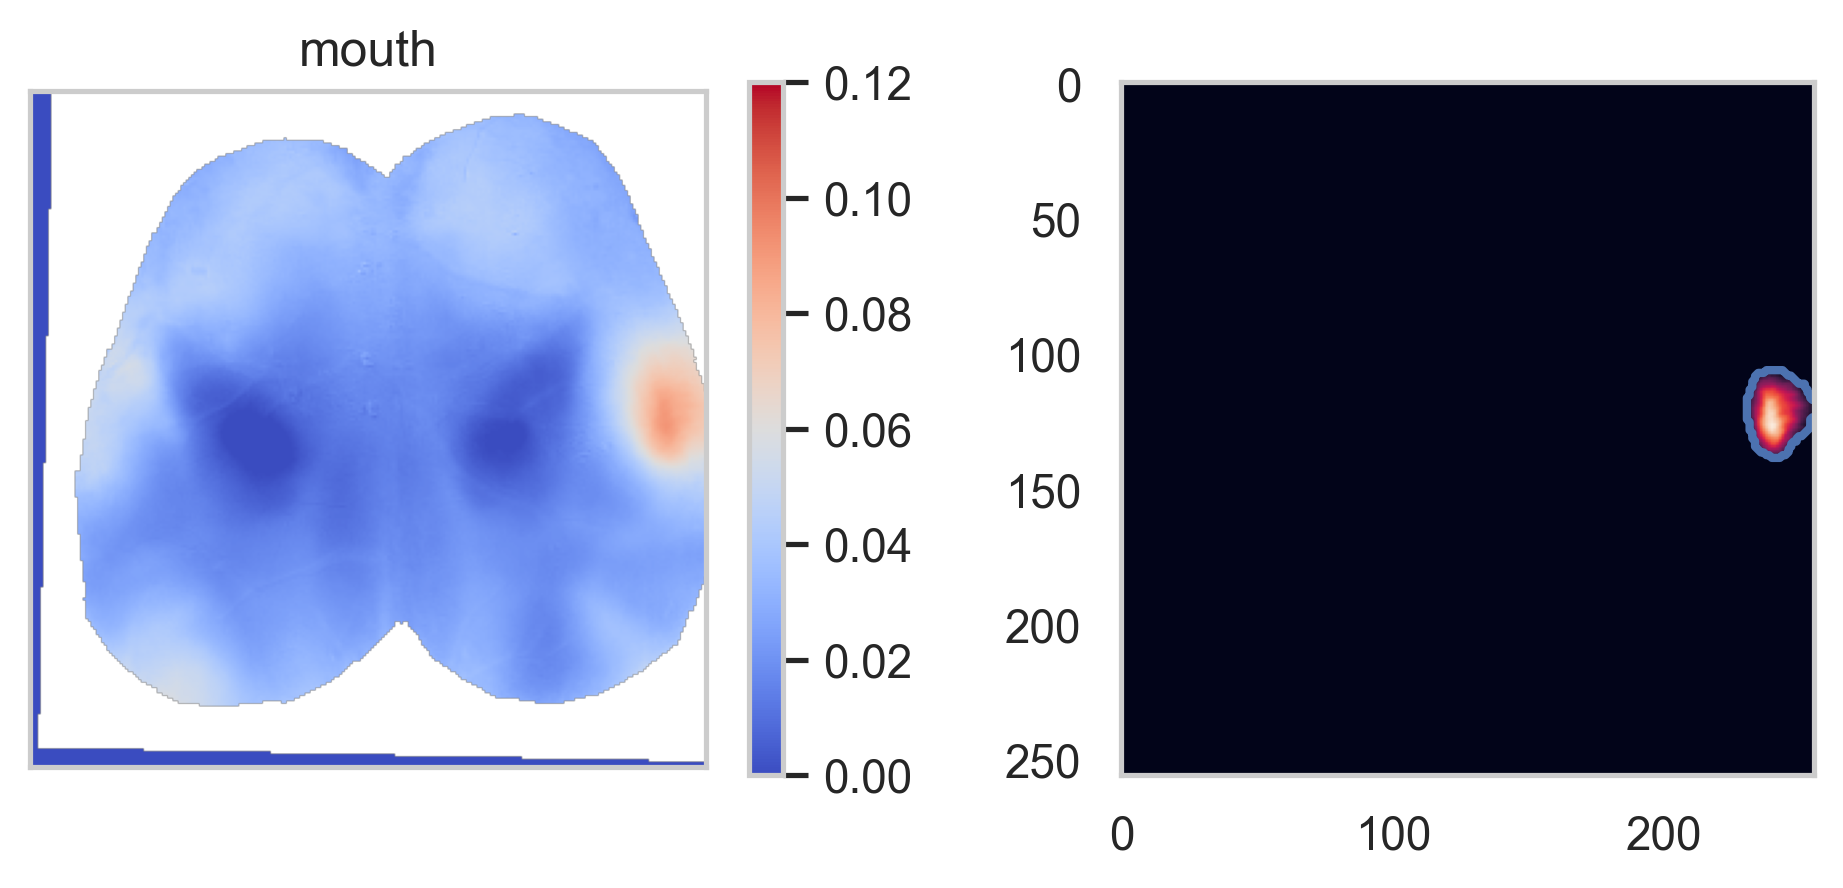

In [39]:
build_bodypart_roi(
    'mouth', range(T_PRE, T_PRE + 80), vmax=0.12, bw_threshold=0.072,
    reject_contour=_reject_default,
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

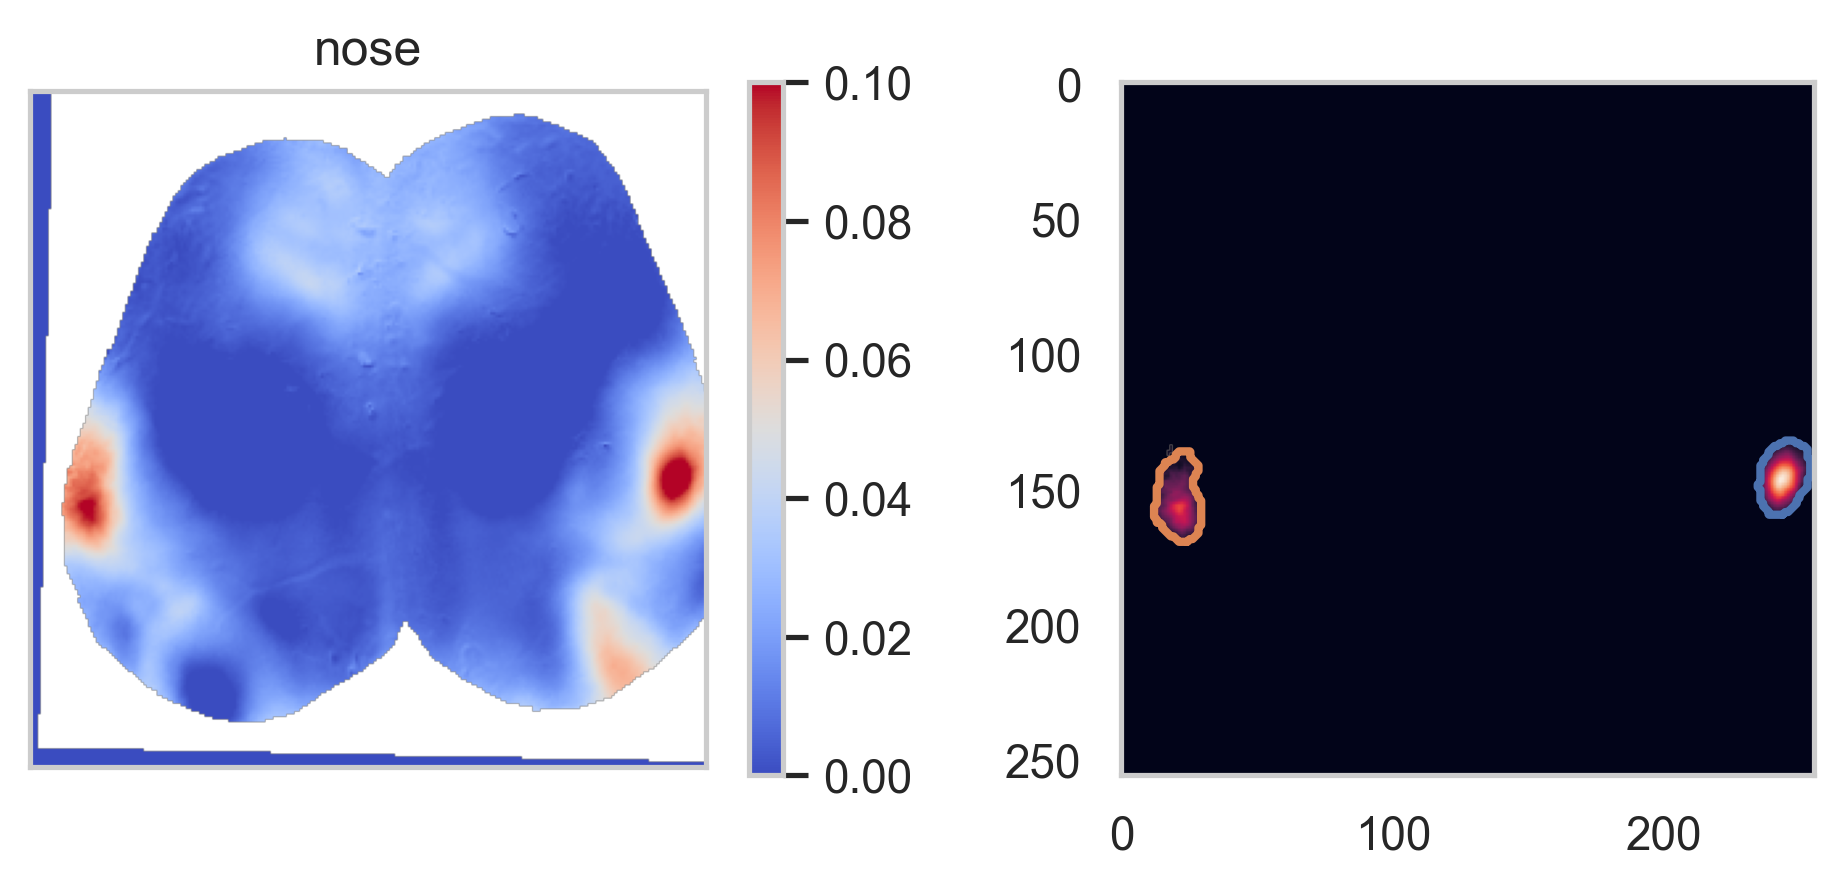

In [40]:
build_bodypart_roi(
    'nose', range(T_PRE, T_PRE + 60), vmax=0.1, bw_threshold=0.07,
    reject_contour=_reject_default,
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

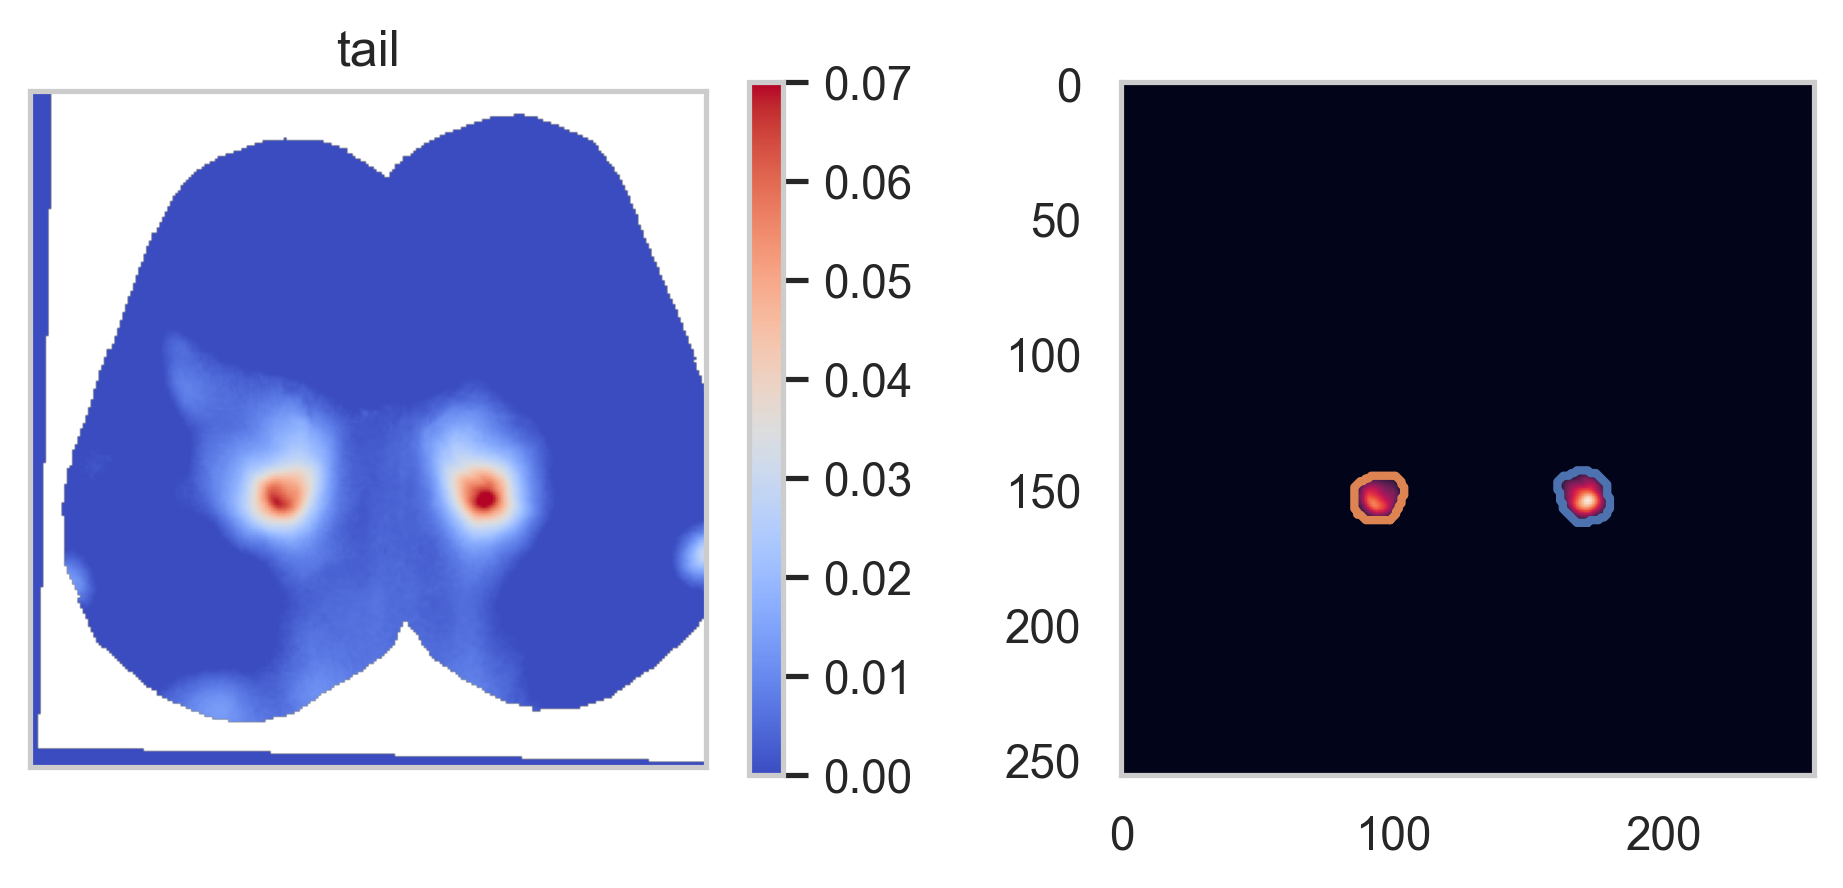

In [41]:
build_bodypart_roi(
    'tail', range(T_PRE, T_PRE + 20), vmax=0.07, bw_threshold=0.04,
    reject_contour=_reject_default,
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

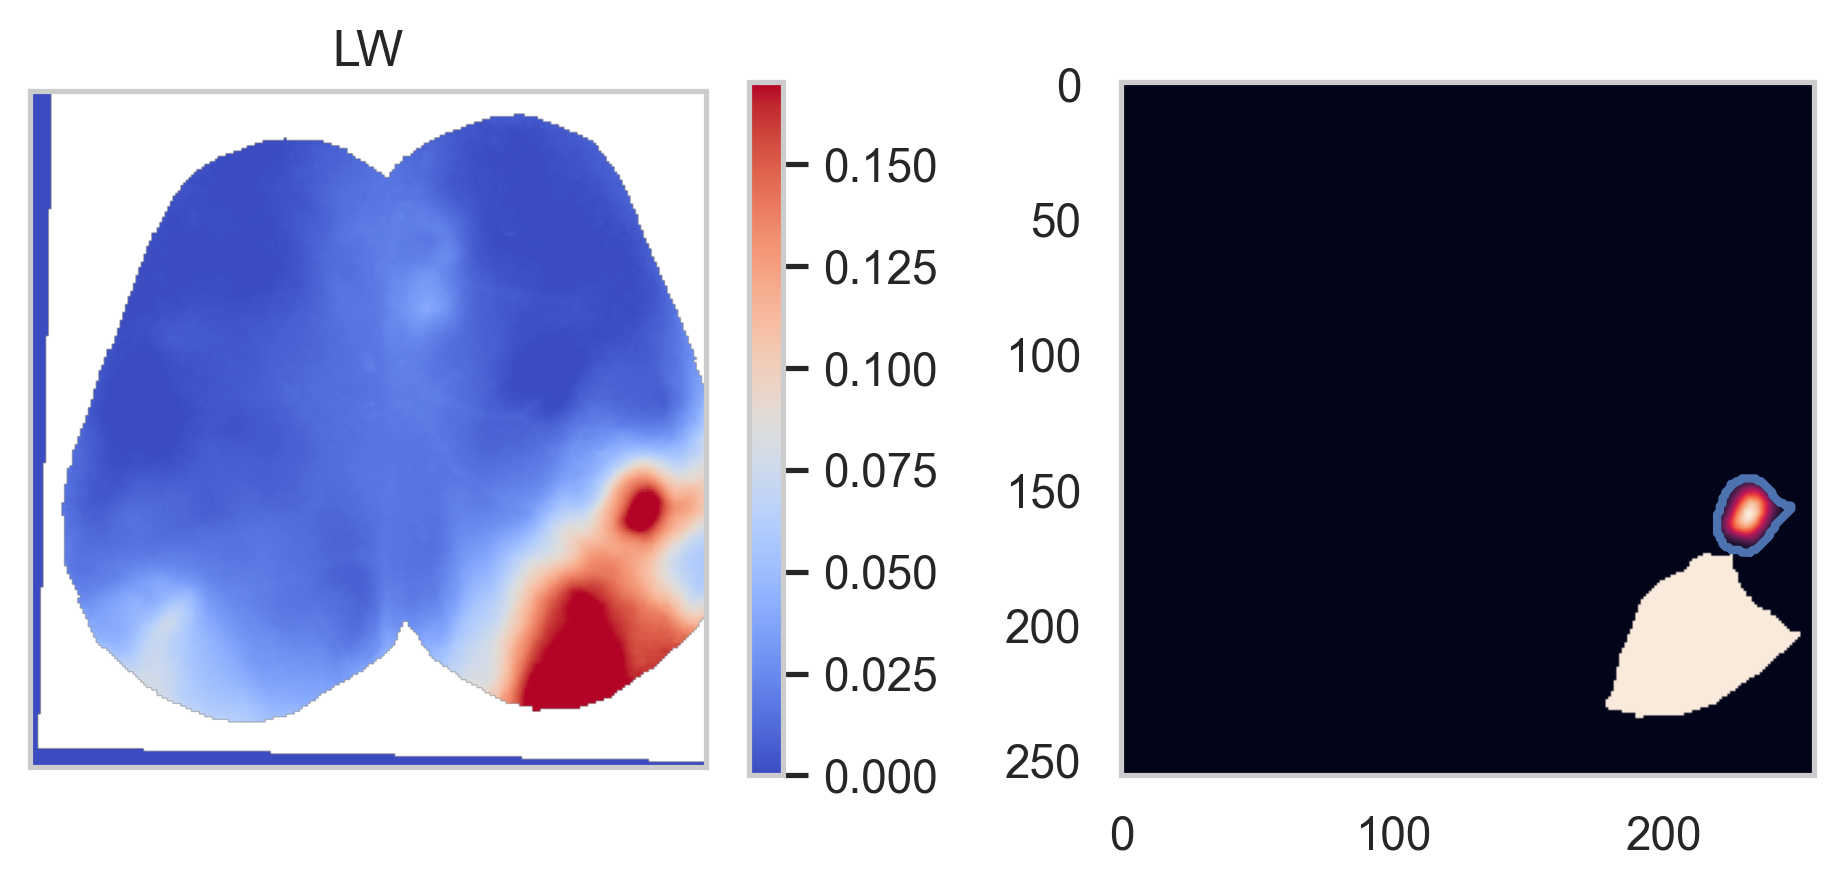

In [42]:
build_bodypart_roi(
    'LW', range(T_PRE, T_PRE + 40), vmax=0.17, bw_threshold=0.125,
    reject_contour=_reject_default, focus_range=(0.1, 1),
    mask_crop=lambda bw: _crop_rows(bw, 173),
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

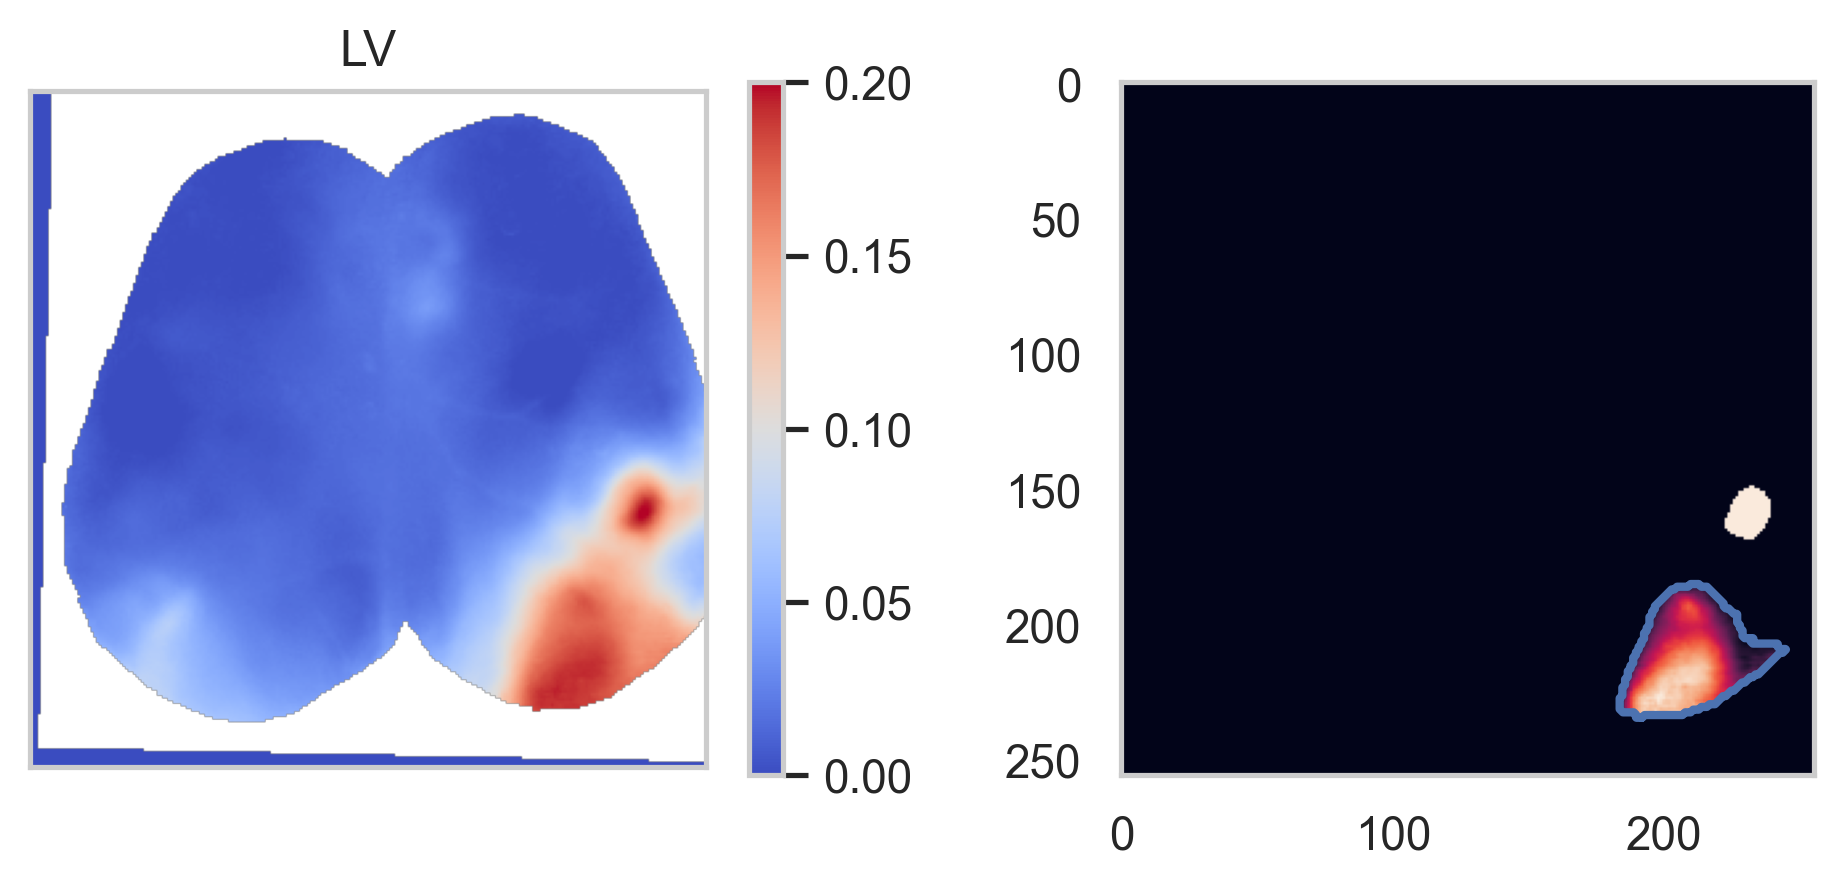

In [43]:
build_bodypart_roi(
    'LV', range(T_PRE, T_PRE + 40), vmax=0.2, bw_threshold=0.15,
    source_key='LW', stat_key='LW', focus_range=(0.2, 1),
    mask_crop=_crop_lv_from_lw,
    reject_contour=lambda c: (
        np.any(c[:, 0] < 180) or np.any(c[:, 1] < 180) or len(c) < 30
    ),
)


array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(256, 256))

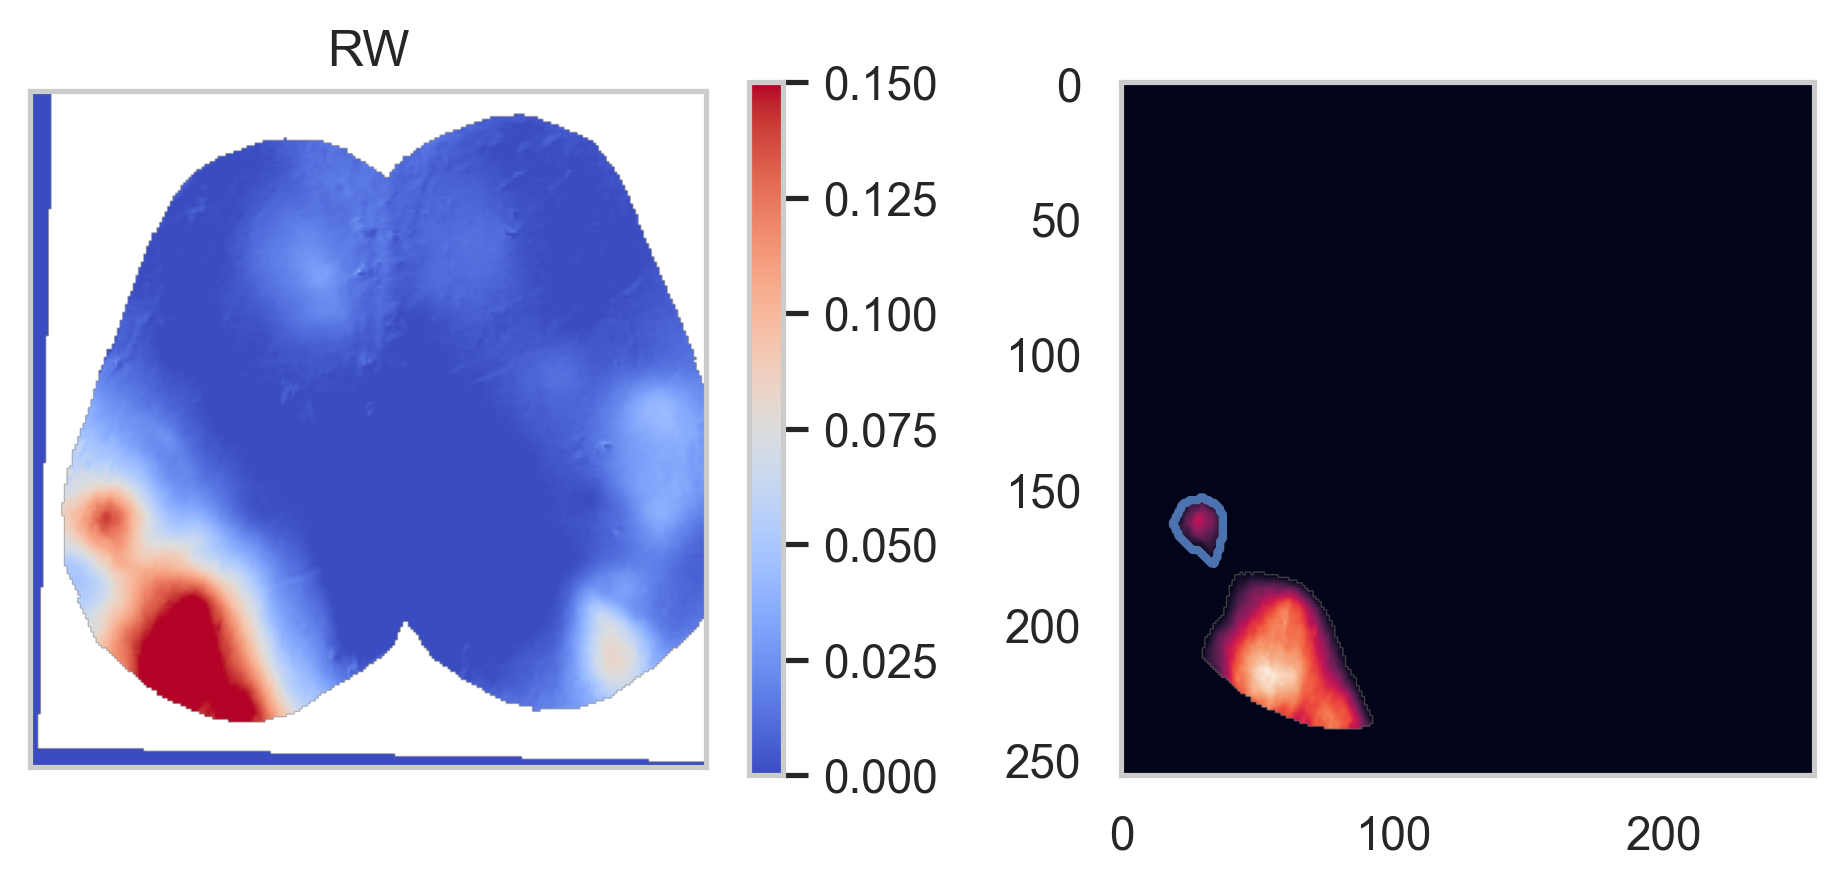

In [44]:
build_bodypart_roi(
    'RW', range(T_PRE, T_PRE + 40), vmax=0.15, bw_threshold=0.105,
    reject_contour=_reject_default,
)


In [45]:
save_path = str(PREPARES / "sensory-boop-test") + "/"
save_model(homunculus_rois, save_path + 'homunculus_rois_' + mouse)


In [46]:
save_model(clean_contours, save_path + 'clean_contours_' + mouse)
